# PyTorch Fundamentals for Medical Imaging

## Objective
Learn the core PyTorch concepts required to build deep learning models for medical imaging.

## Topics
- Tensors and GPU acceleration with Apple Silicon (MPS)
- Automatic differentiation with autograd
- Neural network components with `torch.nn`
- Loss functions and optimization
- Training and evaluation loops

## Scope
This notebook uses synthetic data for educational purposes. It does not perform clinical diagnosis or validate a medical model.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

print(f"PyTorch version: {torch.__version__}")
print(f"Device: {device}")
print(f"MPS available: {torch.backends.mps.is_available()}")

PyTorch version: 2.14.1
Device: mps
MPS available: True


## 1. Tensors and Dimensions

A tensor is the basic data structure in PyTorch. It can represent a scalar, a vector, a matrix, or a higher-dimensional array.

In medical imaging, tensors can represent individual images, batches of images, and multi-channel inputs to neural networks.

In [2]:
import torch

# Scalar: a single number
scalar = torch.tensor(5.0)

# Vector: one-dimensional data
vector = torch.tensor([1.0, 2.0, 3.0])

# Matrix: two-dimensional data
matrix = torch.tensor([
    [1.0, 2.0, 3.0],
    [4.0, 5.0, 6.0]
])

# 3D tensor: for example, a stack of grayscale images
volume = torch.randn(10, 64, 64)

print("Scalar:", scalar.shape)
print("Vector:", vector.shape)
print("Matrix:", matrix.shape)
print("Volume:", volume.shape)
print("Volume data type:", volume.dtype)

Scalar: torch.Size([])
Vector: torch.Size([3])
Matrix: torch.Size([2, 3])
Volume: torch.Size([10, 64, 64])
Volume data type: torch.float32


Image shape: torch.Size([256, 256])
Image batch shape: torch.Size([1, 1, 256, 256])
Minimum pixel value: 6.657838821411133e-05
Maximum pixel value: 0.9999715089797974


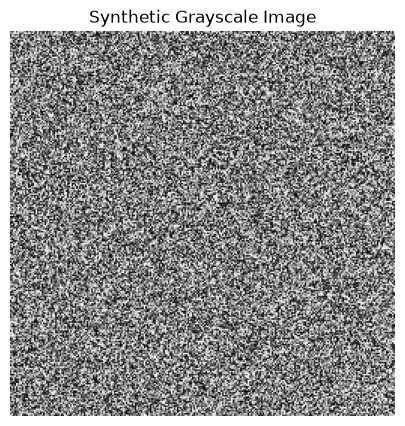

In [3]:
import matplotlib.pyplot as plt
import torch

# Create a synthetic grayscale image
image = torch.rand(256, 256)

# Add batch and channel dimensions
image_batch = image.unsqueeze(0).unsqueeze(0)

print("Image shape:", image.shape)
print("Image batch shape:", image_batch.shape)
print("Minimum pixel value:", image.min().item())
print("Maximum pixel value:", image.max().item())

plt.figure(figsize=(5, 5))
plt.imshow(image.numpy(), cmap="gray")
plt.title("Synthetic Grayscale Image")
plt.axis("off")
plt.show()

## 2. Tensor Devices and Apple Silicon GPU

PyTorch tensors can be stored on the CPU or on a supported accelerator. On Apple Silicon, the Metal Performance Shaders (MPS) backend enables GPU computation.

Tensors and model parameters must be on compatible devices to perform operations together.

In [4]:
# Create a tensor directly on the selected device
x = torch.randn(256, 256, device=device)
y = torch.randn(256, 256, device=device)

# Matrix multiplication on the selected device
result = x @ y

print("Input device:", x.device)
print("Result device:", result.device)
print("Result shape:", result.shape)
print("All values finite:", torch.isfinite(result).all().item())

Input device: mps:0
Result device: mps:0
Result shape: torch.Size([256, 256])
All values finite: True


## 3. Automatic Differentiation with Autograd

PyTorch autograd tracks operations on tensors with `requires_grad=True` and computes gradients through backpropagation.

Gradients indicate how a function changes with respect to its inputs or parameters. Neural networks use these gradients to update their parameters and minimize a loss function.

In [5]:
# Define a parameter that PyTorch should track
w = torch.tensor(3.0, requires_grad=True)

# Define a simple function: y = w² + 2w
y = w**2 + 2 * w

# Compute the derivative of y with respect to w
y.backward()

print("w:", w.item())
print("y:", y.item())
print("Gradient:", w.grad.item())

w: 3.0
y: 15.0
Gradient: 8.0


## 4. Building a Neural Network

PyTorch provides `torch.nn` to define neural network architectures. A model consists of trainable parameters and operations that transform input data into predictions.

In this experiment, we will train a small neural network to learn a synthetic relationship between input values and target values.

Input shape: torch.Size([100, 1])
Target shape: torch.Size([100, 1])
Device: mps:0


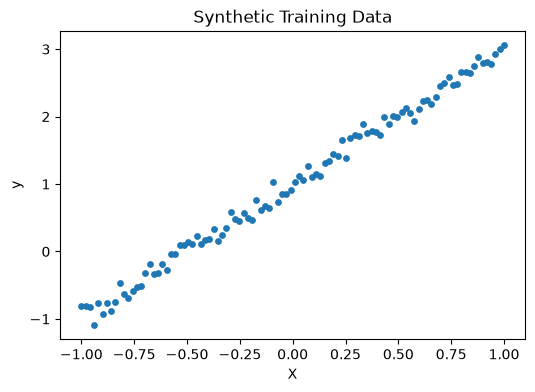

In [6]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Generate synthetic training data
X = torch.linspace(-1, 1, 100).reshape(-1, 1)
y = 2 * X + 1 + 0.1 * torch.randn_like(X)

# Move data to the selected device
X = X.to(device)
y = y.to(device)

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print("Device:", X.device)

plt.figure(figsize=(6, 4))
plt.scatter(X.cpu().numpy(), y.cpu().numpy(), s=15)
plt.xlabel("X")
plt.ylabel("y")
plt.title("Synthetic Training Data")
plt.show()

### 4.1. Model, Loss Function, and Optimizer

We will use a single linear layer to learn the relationship between inputs and targets.

- **Model:** maps each input to a prediction.
- **Loss function:** measures the difference between predictions and targets.
- **Optimizer:** updates model parameters using the computed gradients.

We will use mean squared error (MSE) as the loss function and stochastic gradient descent (SGD) as the optimizer.

In [7]:
# Define the model
model = nn.Linear(in_features=1, out_features=1).to(device)

# Define loss and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

print("Initial weight:", model.weight.item())
print("Initial bias:", model.bias.item())

Initial weight: 0.1563711166381836
Initial bias: -0.8799213171005249


### 4.2. Training Loop

Each training iteration follows four steps:

1. **Forward pass:** generate predictions.
2. **Loss calculation:** measure prediction error.
3. **Backpropagation:** calculate parameter gradients.
4. **Optimization:** update model parameters.

Gradients are reset before each iteration because PyTorch accumulates them by default.

In [8]:
epochs = 200
loss_history = []

for epoch in range(epochs):
    # 1. Forward pass
    predictions = model(X)

    # 2. Calculate loss
    loss = criterion(predictions, y)

    # 3. Reset gradients and backpropagate
    optimizer.zero_grad()
    loss.backward()

    # 4. Update parameters
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 40 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"Loss: {loss.item():.4f}"
        )

Epoch [40/200], Loss: 0.0144
Epoch [80/200], Loss: 0.0096
Epoch [120/200], Loss: 0.0096
Epoch [160/200], Loss: 0.0096
Epoch [200/200], Loss: 0.0096


Learned weight: 1.997
Learned bias: 1.006
Final training loss: 0.0096


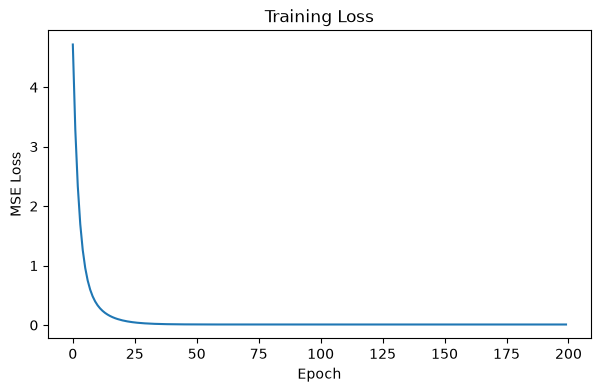

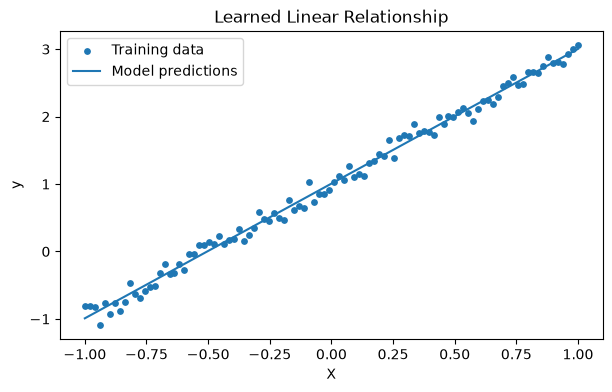

In [9]:
# Evaluate without tracking gradients
model.eval()

with torch.no_grad():
    predictions = model(X)

print(f"Learned weight: {model.weight.item():.3f}")
print(f"Learned bias: {model.bias.item():.3f}")
print(f"Final training loss: {loss_history[-1]:.4f}")

# Plot training loss
plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss")
plt.show()

# Compare data and predictions
plt.figure(figsize=(7, 4))
plt.scatter(X.cpu().numpy(), y.cpu().numpy(), s=15, label="Training data")
plt.plot(
    X.cpu().numpy(),
    predictions.cpu().numpy(),
    label="Model predictions",
)
plt.xlabel("X")
plt.ylabel("y")
plt.title("Learned Linear Relationship")
plt.legend()
plt.show()